In [3]:
!pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

In [4]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the Adult dataset from UCI
adult = fetch_ucirepo(id=2)

# Separate input features and target
X = adult.data.features
y = adult.data.targets

# Combine them into one DataFrame
df = pd.concat([X, y], axis=1)

# Rename target column
df = df.rename(columns={df.columns[-1]: "income"})

# Save the original downloaded dataset
df.to_csv("adult_income_dataset.csv", index=False)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
# Normalize income labels by removing trailing periods
df["income"] = (
    df["income"]
    .astype("string")
    .str.replace(".", "", regex=False)
    .str.strip()
)

# Verify the corrected distribution
print("Corrected income distribution:")

print(df["income"].value_counts())

print("\nPercentage distribution:")

print(
    (df["income"].value_counts(normalize=True) * 100).round(2)
)

Corrected income distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: Int64

Percentage distribution:
income
<=50K    76.07
>50K     23.93
Name: proportion, dtype: Float64


In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Verify the dataset
print("Dataset shape after duplicate removal:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape after duplicate removal: (48794, 15)
Remaining duplicate rows: 0

Missing values in each column:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64


In [26]:
# Separate input features and target variable
X = df.drop(columns=["income"])
y = df["income"].map({
    "<=50K": 0,
    ">50K": 1
}).astype(int)

# Verify the separation
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts())

print("\nTarget class percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (48794, 14)
Target shape: (48794,)

Target class distribution:
income
0    37113
1    11681
Name: count, dtype: int64

Target class percentages:
income
0    76.06
1    23.94
Name: proportion, dtype: float64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (39035, 14)
Testing features: (9759, 14)
Training target: (39035,)
Testing target: (9759,)

Training class distribution:
income
0    76.059946
1    23.940054
Name: proportion, dtype: float64

Testing class distribution:
income
0    76.063121
1    23.936879
Name: proportion, dtype: float64


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")

Numerical features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Preprocessing pipeline created successfully.


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Define the classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Five classification models configured successfully.")

for model_name in models:
    print(model_name)

Five classification models configured successfully.
Logistic Regression
Decision Tree
KNN
Naive Bayes
Random Forest


In [11]:
from sklearn.pipeline import Pipeline

trained_models = {}

for model_name, model in models.items():

    # Combine preprocessing and classification model
    full_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train the model using training data
    full_pipeline.fit(X_train, y_train)

    # Store the trained pipeline
    trained_models[model_name] = full_pipeline

    print(f"{model_name} trained successfully.")

print("\nAll five models have been trained.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
KNN trained successfully.
Naive Bayes trained successfully.
Random Forest trained successfully.

All five models have been trained.


In [12]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for model_name, trained_model in trained_models.items():

    # Predict class labels
    y_pred = trained_model.predict(X_test)

    # Predict probability for the positive class (>50K)
    y_prob = trained_model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Display results
print("Classification Model Performance Comparison:")
display(results_df.round(4))

Classification Model Performance Comparison:


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8556,0.9101,0.7403,0.6113,0.6696,0.5827
1,Decision Tree,0.8165,0.7561,0.6114,0.6404,0.6255,0.5043
2,KNN,0.8393,0.8677,0.6829,0.6139,0.6465,0.5442
3,Naive Bayes,0.6024,0.8195,0.3692,0.9324,0.5289,0.3761
4,Random Forest,0.8540,0.9062,0.7238,0.6306,0.6740,0.5828


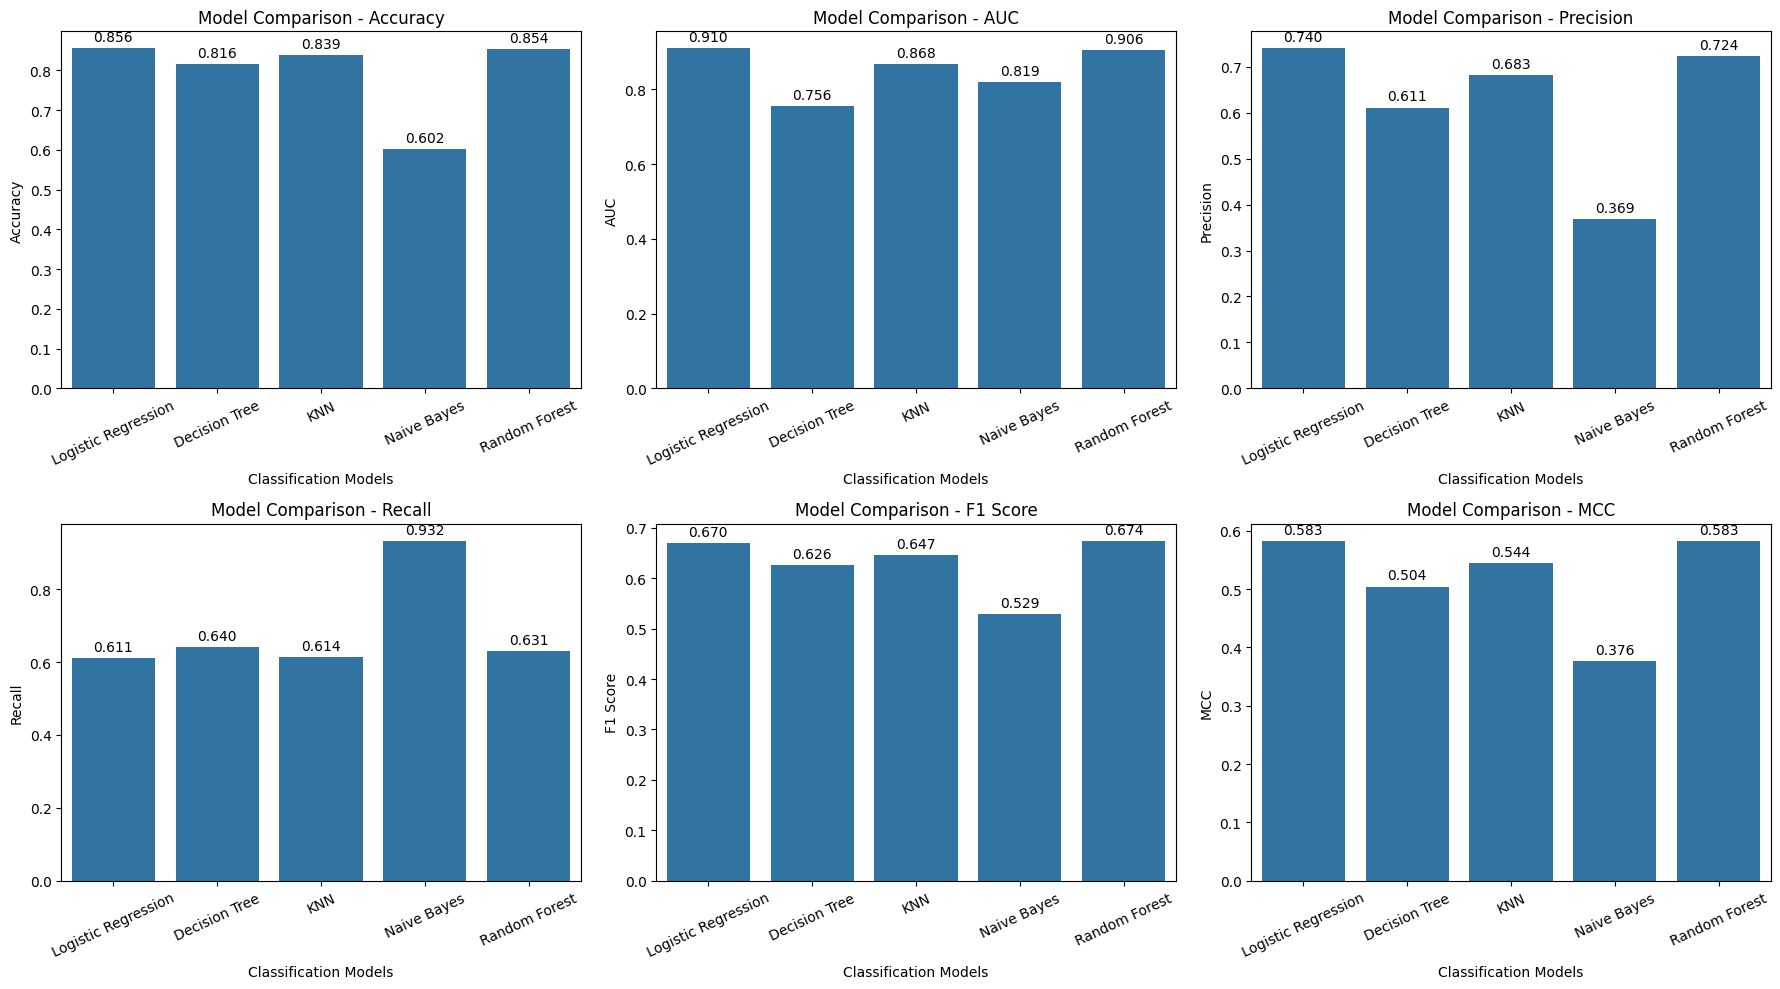

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

    ax.set_title(f"Model Comparison - {metric}")
    ax.set_xlabel("Classification Models")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

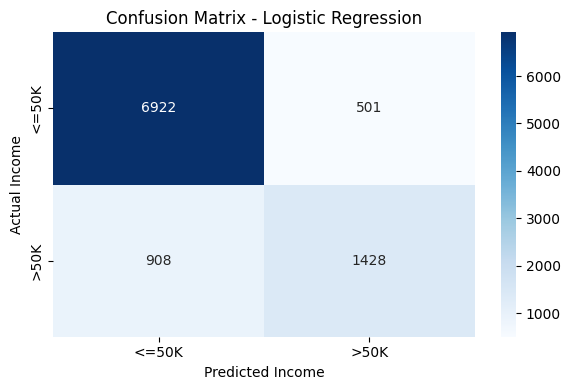

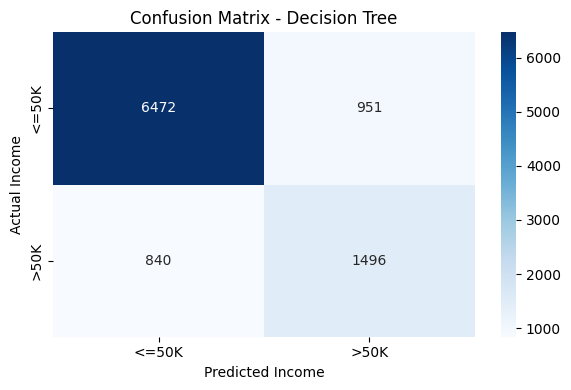

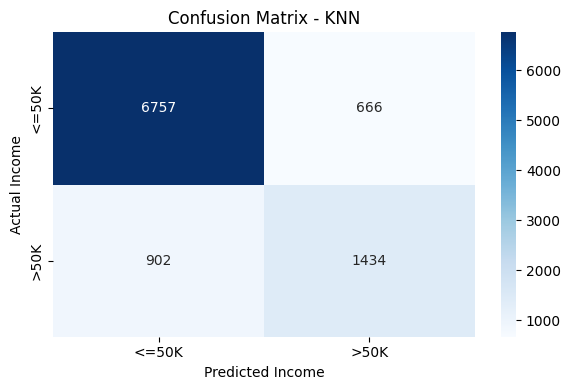

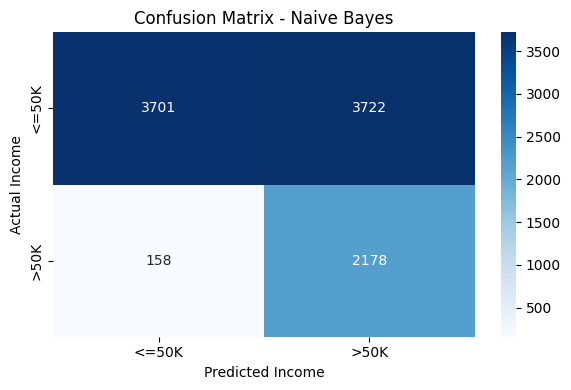

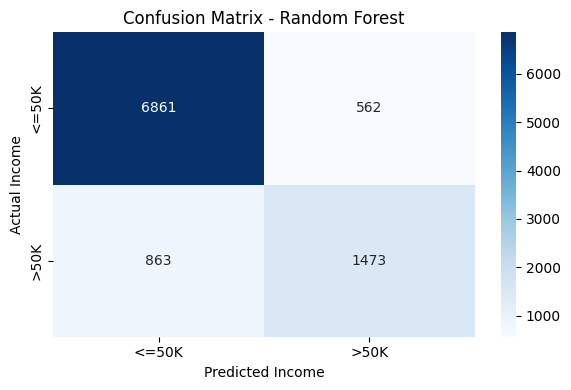

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for model_name, trained_model in trained_models.items():

    y_pred = trained_model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Income")
    plt.ylabel("Actual Income")
    plt.tight_layout()
    plt.show()

In [18]:
import os
import joblib

# Create model directory
os.makedirs("model", exist_ok=True)

# Save all trained models
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Random Forest": "random_forest.joblib"
}

for model_name, trained_model in trained_models.items():

    file_name = model_files[model_name]

    joblib.dump(
        trained_model,
        os.path.join("model", file_name)
    )

    print(f"{model_name} saved successfully.")

print("\nAll five models saved in the model directory.")

Logistic Regression saved successfully.
Decision Tree saved successfully.
KNN saved successfully.
Naive Bayes saved successfully.
Random Forest saved successfully.

All five models saved in the model directory.


In [19]:
# Combine test features and actual target values
test_data = X_test.copy()

test_data["income"] = y_test

# Save test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully.")
print("Test dataset shape:", test_data.shape)

# Verify the saved dataset
print("\nFirst five records:")
display(test_data.head())

Test dataset saved successfully.
Test dataset shape: (9759, 15)

First five records:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
31141,53,Private,191565,1st-4th,2,Divorced,Other-service,Unmarried,Black,Female,0,0,40,Dominican-Republic,0
2562,46,Private,174209,HS-grad,9,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,45,United-States,0
24545,46,Private,140782,Assoc-acdm,12,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,50,United-States,0
34007,32,Private,227282,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,50,United-States,0
19149,22,Private,138513,Some-college,10,Never-married,Craft-repair,Own-child,White,Male,0,0,40,United-States,0


In [20]:
requirements = """pandas
numpy
scikit-learn>=1.2
matplotlib
seaborn
ucimlrepo
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully.")

requirements.txt created successfully.


In [21]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data", "__pycache__"]]

    for file in files:
        if file.endswith((".joblib", ".csv", ".txt", ".md", ".png")):
            print(os.path.join(root, file))

./adult_income_dataset.csv
./requirements.txt
./test_data.csv
./model/knn.joblib
./model/decision_tree.joblib
./model/logistic_regression.joblib
./model/random_forest.joblib
./model/naive_bayes.joblib


In [31]:

readme_content = r"""# Adult Income Classification Using Machine Learning

## 1. Problem Statement

The objective of this assignment is to develop and compare five machine learning classification algorithms to predict whether an individual's annual income exceeds $50,000 based on demographic and employment-related attributes.

This is a binary classification problem.

## 2. Dataset Description

Dataset: Adult Census Income Dataset

Source: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/2/adult)

The dataset contains demographic and employment-related information.

- Original records: 48,842
- Records after duplicate removal: 48,794
- Input features: 14
- Target variable: income
- Classification classes: `<=50K` and `>50K`

The dataset contains 6 numerical features and 8 categorical features.

## 3. Data Preprocessing

The following preprocessing operations were performed:

1. Checked and handled missing values.
2. Removed duplicate records.
3. Normalized target labels by removing trailing periods.
4. Encoded the target variable:
   - `<=50K` = 0
   - `>50K` = 1
5. Separated input features and target variable.
6. Split the dataset into 80% training and 20% testing using stratified sampling.
7. Applied median imputation for numerical features.
8. Applied most-frequent imputation for categorical features.
9. Applied StandardScaler to numerical features.
10. Applied OneHotEncoder to categorical features.

Preprocessing was implemented using a Pipeline and ColumnTransformer to prevent data leakage. The preprocessing steps were fitted only on the training data.

## 4. Class Distribution

After duplicate removal:

- `<=50K`: 37,113 records (76.06%)
- `>50K`: 11,681 records (23.94%)

The dataset is imbalanced, with `<=50K` as the majority class. Therefore, multiple evaluation metrics were considered instead of relying only on accuracy.

## 5. Classification Models

The following five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Random Forest

All models were trained using the same preprocessing pipeline and training dataset.

## 6. Model Evaluation

The models were evaluated using the following metrics:

- Accuracy
- AUC
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

Precision, Recall and F1 Score were calculated considering `>50K` as the positive class.

### Performance Comparison

| Model | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8556 | 0.9101 | 0.7403 | 0.6113 | 0.6696 | 0.5827 |
| Decision Tree | 0.8165 | 0.7561 | 0.6114 | 0.6404 | 0.6255 | 0.5043 |
| KNN | 0.8393 | 0.8677 | 0.6829 | 0.6139 | 0.6465 | 0.5442 |
| Naive Bayes | 0.6024 | 0.8195 | 0.3692 | 0.9324 | 0.5289 | 0.3761 |
| Random Forest | 0.8540 | 0.9062 | 0.7238 | 0.6306 | 0.6740 | 0.5828 |

### Graphical Representation of All Six Metrics

The following graph compares all five classification models using the six evaluation metrics: Accuracy, AUC, Precision, Recall, F1 Score and MCC.

![Model Performance Comparison](https://github.com/Sitalavakusha54321/Adult-Income-Classification/raw/main/images/model_performance_comparison.png)

## 7. Model Observations

### Logistic Regression

Achieved the highest Accuracy (85.56%) and AUC (0.9101), demonstrating strong overall classification performance. It also achieved the highest Precision of 0.7403.

### Decision Tree

Achieved an Accuracy of 81.65% and AUC of 0.7561. Its performance was lower than the leading models on most evaluation metrics.

### K-Nearest Neighbors

Achieved an Accuracy of 83.93% and AUC of 0.8677, showing reasonable classification performance.

### Gaussian Naive Bayes

Achieved the highest Recall (93.24%), correctly identifying a large proportion of actual `>50K` cases. However, its Precision was 36.92%, indicating a high number of false positive predictions.

### Random Forest

Achieved the highest F1 Score (0.6740) and MCC (0.5828), indicating a good balance between Precision and Recall and strong overall classification performance.

## 8. Confusion Matrix Analysis

The confusion matrices were generated for all five models to examine True Positives, True Negatives, False Positives and False Negatives.

| Model | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Logistic Regression | 6922 | 501 | 908 | 1428 |
| Decision Tree | 6472 | 951 | 840 | 1496 |
| KNN | 6757 | 666 | 902 | 1434 |
| Naive Bayes | 3701 | 3722 | 158 | 2178 |
| Random Forest | 6861 | 562 | 863 | 1473 |

### Confusion Matrix Visualizations

#### Logistic Regression

![Logistic Regression Confusion Matrix](images/logistic_regression_confusion_matrix.png)

#### Decision Tree

![Decision Tree Confusion Matrix](images/decision_tree_confusion_matrix.png)

#### KNN

![KNN Confusion Matrix](images/knn_confusion_matrix.png)

#### Naive Bayes

![Naive Bayes Confusion Matrix](images/naive_bayes_confusion_matrix.png)

#### Random Forest

![Random Forest Confusion Matrix](images/random_forest_confusion_matrix.png)

Naive Bayes identified the largest number of actual `>50K` cases but also generated the highest number of false positives.

## 9. Overall Winner for the Dataset

Based on the evaluation results, **Random Forest is selected as the overall best-performing model** for the Adult Income Classification dataset.

- F1 Score: 0.6740 (Highest among the five models)
- MCC: 0.5828 (Highest among the five models)
- Accuracy: 0.8540
- AUC: 0.9062

Random Forest demonstrated a good balance between Precision and Recall and achieved the highest F1 Score and MCC.

Logistic Regression also demonstrated competitive performance, achieving the highest Accuracy of 0.8556 and AUC of 0.9101.

The MCC values of Random Forest (0.5828) and Logistic Regression (0.5827) are nearly identical. Therefore, both models demonstrated comparable overall performance.

Considering the F1 Score and MCC, **Random Forest is selected as the overall winner for this dataset.**

## 10. Repository Structure

```text
Adult-Income-Classification/
|
|-- model/
|   |-- logistic_regression.joblib
|   |-- decision_tree.joblib
|   |-- knn.joblib
|   |-- naive_bayes.joblib
|   |-- random_forest.joblib
|
|-- images/
|   |-- model_performance_comparison.png
|   |-- logistic_regression_confusion_matrix.png
|   |-- decision_tree_confusion_matrix.png
|   |-- knn_confusion_matrix.png
|   |-- naive_bayes_confusion_matrix.png
|   |-- random_forest_confusion_matrix.png
|
|-- adult_income_classification.ipynb
|-- adult_income_dataset.csv
|-- test_data.csv
|-- requirements.txt
|-- README.md
```

## 11. Conclusion

This assignment implemented and evaluated five machine learning classification algorithms on the Adult Census Income dataset.

Random Forest achieved the highest F1 Score and MCC, while Logistic Regression achieved the highest Accuracy and AUC. The results demonstrate that different classification algorithms perform differently across evaluation metrics, particularly when working with an imbalanced dataset.

The assignment highlights the importance of appropriate preprocessing, stratified sampling, and comprehensive model evaluation.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("Updated README.md created successfully.")

Updated README.md created successfully.


In [24]:

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# Create images folder
os.makedirs("images", exist_ok=True)

# 1. Save the combined six-metric comparison graph
plt.figure(1)
plt.savefig(
    "images/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# 2. Save the five confusion matrix graphs
confusion_matrices = {
    "logistic_regression": [6922, 501, 908, 1428],
    "decision_tree": [6472, 951, 840, 1496],
    "knn": [6757, 666, 902, 1434],
    "naive_bayes": [3701, 3722, 158, 2178],
    "random_forest": [6861, 562, 863, 1473]
}

for model_name, values in confusion_matrices.items():
    cm = [
        [values[0], values[1]],
        [values[2], values[3]]
    ]

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{model_name.replace('_', ' ').title()} Confusion Matrix")

    plt.savefig(
        f"images/{model_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

# 3. Verify saved images
print("Images saved:")
for filename in sorted(os.listdir("images")):
    print(filename)


Images saved:
decision_tree_confusion_matrix.png
knn_confusion_matrix.png
logistic_regression_confusion_matrix.png
model_performance_comparison.png
naive_bayes_confusion_matrix.png
random_forest_confusion_matrix.png


In [25]:

import os
import zipfile

assignment_files = [
    "README.md",
    "requirements.txt",
    "adult_income_dataset.csv",
    "test_data.csv"
]

assignment_folders = ["model", "images"]

with zipfile.ZipFile("assignment.zip", "w", zipfile.ZIP_DEFLATED) as zipf:

    for file in assignment_files:
        if os.path.exists(file):
            zipf.write(file)

    for folder in assignment_folders:
        for root, dirs, files in os.walk(folder):
            for file in files:
                filepath = os.path.join(root, file)
                zipf.write(filepath)

print("Assignment ZIP created successfully!")

Assignment ZIP created successfully!


In [27]:

import os
import joblib

os.makedirs("model_compressed", exist_ok=True)

model_files = [
    "logistic_regression",
    "decision_tree",
    "knn",
    "naive_bayes",
    "random_forest"
]

for model_name in model_files:
    original_path = f"model/{model_name}.joblib"
    compressed_path = f"model_compressed/{model_name}.joblib"

    trained_model = joblib.load(original_path)

    joblib.dump(
        trained_model,
        compressed_path,
        compress=3
    )

    size_mb = os.path.getsize(compressed_path) / (1024 * 1024)

    print(f"{model_name}: {size_mb:.2f} MB")

print("Compressed model files created successfully!")

logistic_regression: 0.00 MB
decision_tree: 0.16 MB
knn: 1.70 MB
naive_bayes: 0.01 MB
random_forest: 17.94 MB
Compressed model files created successfully!


In [28]:

import shutil

shutil.make_archive(
    "assignment_models",
    "zip",
    "model_compressed"
)

print("Compressed model ZIP created successfully!")

Compressed model ZIP created successfully!
